# Roger Voss Wine Review Models

This notebook tests whether words in Roger Voss's reviews can predict **country**, **province**, and **region_1**. We compare a dummy baseline, logistic regression, and a decision tree. **Accuracy** is the overall fraction correct. **Macro F1** gives every location class equal importance, including rare ones.

## 1. Setup

Import the data, modeling, evaluation, and plotting tools. SEED = 42 makes the random split reproducible.

In [7]:
%pip install matplotlib numpy pandas scikit-learn joblib pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_config
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGETS = ["country", "province", "region_1"]
MIN_TRAIN_REVIEWS = 0
N_JOBS = 6  # change depending on number of cores
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

## 2. Load and filter

Load the cleaned dataset and retain only Roger Voss reviews. .copy() creates an independent DataFrame so later work does not affect the original data.

In [9]:
df = pd.read_parquet("data_clean/wine_reviews_clean.parquet")
df

,country,description,designation,points,price,province,region_1,region_2,taster_name,title,variety,winery,vintage,log_price,price_missing,country_group
0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia,2013,NaN,True,Italy
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos,2011,2.708050,False,Portugal
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm,2013,2.639057,False,US
3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian,2013,2.564949,False,US
4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks,2012,4.174387,False,US
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119917,Germany,Notes of honeysuckle and cantaloupe sweeten th...,Brauneberger Juffer-Sonnenuhr Spätlese,90,28.0,Mosel,NaN,NaN,Anna Lee C. Iijima,Dr. H. Thanisch (Erben Müller-Burggraef) 2013 ...,Riesling,Dr. H. Thanisch (Erben Müller-Burggraef),2013,3.332205,False,Germany
119918,US,Citation is given as much as a decade of bottl...,NaN,90,75.0,Oregon,Oregon,Oregon Other,Paul Gregutt,Citation 2004 Pinot Noir (Oregon),Pinot Noir,Citation,2004,4.317488,False,US
119919,France,Well-drained gravel soil gives this wine its c...,Kritt,90,30.0,Alsace,Alsace,NaN,Roger Voss,Domaine Gresser 2013 Kritt Gewurztraminer (Als...,Gewürztraminer,Domaine Gresser,2013,3.401197,False,France
119920,France,"A dry style of Pinot Gris, this is crisp with ...",NaN,90,32.0,Alsace,Alsace,NaN,Roger Voss,Domaine Marcel Deiss 2012 Pinot Gris (Alsace),Pinot Gris,Domaine Marcel Deiss,2012,3.465736,False,France


In [10]:
df = df[df["taster_name"] == "Roger Voss"].copy()
df["taster_name"].value_counts()

taster_name
Roger Voss    23556
Name: count, dtype: int64

## 3. Create the 70/15/15 split

The **training set** teaches each model, the **validation set** compares models, and the **test set** is saved for the final unbiased check. Stratifying by country_group keeps the broad country mix similar. The assertions verify that no review appears in two splits.

In [12]:
# Use country_group only as a temporary label for balanced splitting.
strata = df["country_group"].fillna("Unknown")
strata_counts = strata.value_counts()

small_groups = strata_counts[strata_counts < 7].index
largest_group = strata_counts.idxmax()

# This does not modify df or its real country labels.
strata = strata.mask(strata.isin(small_groups), largest_group)

train, rest = train_test_split(
    df,
    test_size=0.30,
    stratify=strata,
    random_state=SEED,
)

rest_strata = strata.loc[rest.index].copy()
rest_counts = rest_strata.value_counts()
too_small_in_rest = rest_counts[rest_counts < 2].index

if len(too_small_in_rest) > 0:
    rest_strata = rest_strata.mask(
        rest_strata.isin(too_small_in_rest),
        rest_counts.idxmax(),
    )

val, test = train_test_split(
    rest,
    test_size=0.50,
    stratify=rest_strata,
    random_state=SEED,
)

assert set(train.index).isdisjoint(val.index)
assert set(train.index).isdisjoint(test.index)
assert set(val.index).isdisjoint(test.index)

print("Small groups combined for splitting:", list(small_groups))
print("Split sizes:", len(train), len(val), len(test))

Small groups combined for splitting: ['US', 'Unknown', 'Greece']
Split sizes: 16489 3533 3534


## 4. Country distributions

Read each column as the percentage of that split from each country. Similar percentages across train, validation, and test indicate a balanced split. If one country dominates, plain accuracy can look better than performance on rare countries; macro F1 helps reveal that problem.

In [13]:
country_distributions = pd.concat({
    name: split["country"].value_counts(normalize=True, dropna=False).mul(100)
    for name, split in [("train", train), ("validation", val), ("test", test)]
}, axis=1).fillna(0)
country_distributions.round(1)

,train,validation,test
country,,,
France,72.8,72.8,72.8
Portugal,22.2,22.2,22.2
Austria,4.5,4.5,4.5
Italy,0.4,0.4,0.4
South Africa,0.1,0.1,0.1
NaN,0.0,0.0,0.0
US,0.0,0.0,0.0
Greece,0.0,0.0,0.0


In [14]:
# Keep Roger Voss splits in memory. Do not overwrite the shared team split files.
split_sizes = pd.Series({"train": len(train), "validation": len(val), "test": len(test)})
(split_sizes / split_sizes.sum()).round(3)

train         0.70
validation    0.15
test          0.15
dtype: float64

## 5. TF-IDF text features

TF-IDF turns descriptions into numbers by weighting informative words and two-word phrases. The vocabulary is learned with it_transform on **training text only**. Validation and test text use 	ransform, so they cannot leak information into training.

In [15]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=20000)
X_train = vectorizer.fit_transform(train["description"])
X_val = vectorizer.transform(val["description"])
X_test = vectorizer.transform(test["description"])
X_train.shape

(16489, 16706)

## 6. Usable location labels

The summary reports how many country, province, and region labels occur in training and how much data is missing. A target with many classes, many missing values, or few examples per class is usually harder to predict. subset keeps rows whose target is known and appeared during training.

In [16]:
keep = {}
summary = []
for target in TARGETS:
    counts = train[target].value_counts()
    keep[target] = counts[counts >= MIN_TRAIN_REVIEWS].index
    summary.append({
        "target": target,
        "all_classes": train[target].nunique(),
        "kept_classes": len(keep[target]),
        "pct_missing": train[target].isna().mean() * 100,
        "pct_rows_kept": train[target].isin(keep[target]).mean() * 100,
    })
pd.DataFrame(summary).set_index("target").round(1)

,all_classes,kept_classes,pct_missing,pct_rows_kept
target,,,,
country,7,7,0.0,100.0
province,82,82,0.0,100.0
region_1,322,322,27.1,72.9


In [17]:
def subset(split, X, target):
    mask = split[target].isin(keep[target]).to_numpy()
    return X[mask], split[target].to_numpy()[mask]

## 7. Models

- **Dummy:** always predicts the most common training label; this is the minimum baseline to beat.
- **Logistic regression:** learns which TF-IDF terms support each location.
- **Decision tree:** learns word-based decision rules. Its depth and leaf limits help control overfitting.

In [18]:
def make_models():
    return {
        "Most frequent (dummy)": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": OneVsRestClassifier(LogisticRegression(C=10, solver="liblinear"), n_jobs=N_JOBS),
        "Decision tree": DecisionTreeClassifier(max_depth=30, min_samples_leaf=5, random_state=SEED),
    }

## 8. Validation results

A useful model should beat the dummy on both validation accuracy and macro F1. Compare training and validation accuracy too: a large drop suggests overfitting. If accuracy is high but macro F1 is low, the model is probably predicting common locations much better than rare ones.

In [20]:
fitted = {}
results = []
for target in TARGETS:
    Xt, yt = subset(train, X_train, target)
    Xv, yv = subset(val, X_val, target)
    for name, model in make_models().items():
        start = time.perf_counter()
        with parallel_config(max_nbytes=None):
            model.fit(Xt, yt)
        fit_seconds = time.perf_counter() - start
        pred = model.predict(Xv)
        fitted[target, name] = model
        results.append({
            "target": target,
            "model": name,
            "train_accuracy": accuracy_score(yt, model.predict(Xt)),
            "accuracy": accuracy_score(yv, pred),
            "macro_F1": f1_score(yv, pred, average="macro", zero_division=0),
            "fit_seconds": fit_seconds,
        })
results = pd.DataFrame(results).set_index(["target", "model"])
results.round(3)

train_accuracy  accuracy  macro_F1  \
target   model                                                       
country  Most frequent (dummy)           0.728     0.728     0.169   
         Logistic regression             0.970     0.830     0.412   
         Decision tree                   0.850     0.821     0.402   
province Most frequent (dummy)           0.235     0.233     0.006   
         Logistic regression             0.984     0.548     0.139   
         Decision tree                   0.504     0.370     0.090   
region_1 Most frequent (dummy)           0.085     0.076     0.001   
         Logistic regression             0.999     0.323     0.077   
         Decision tree                   0.310     0.177     0.038   

                                fit_seconds  
target   model                               
country  Most frequent (dummy)        0.015  
         Logistic regression          0.746  
         Decision tree                2.169  
province Most frequent (dummy)        0.007  
         Logistic regression          8.982  
         Decision tree               18.064  
region_1 Most frequent (dummy)        0.014  
         Logistic regression         23.639  
         Decision tree               21.668

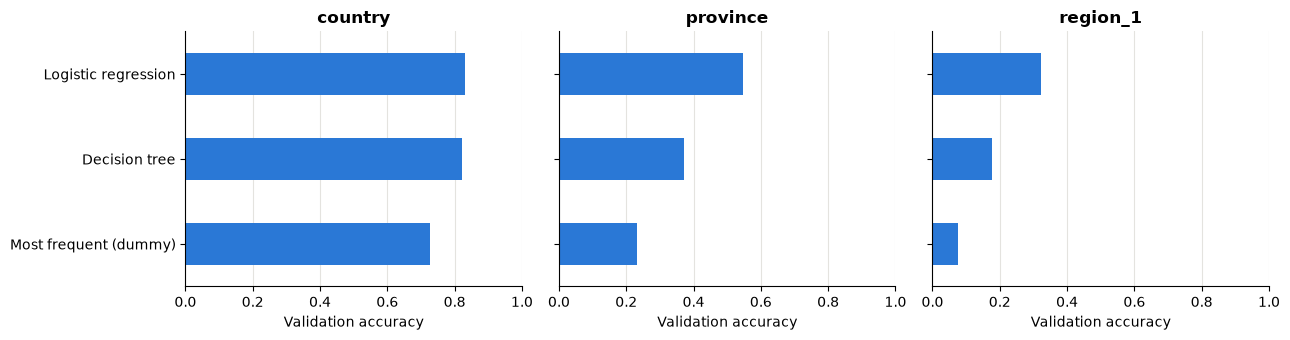

In [21]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(13, 3.5), sharex=True)
for ax, target in zip(axes, TARGETS):
    results.loc[target, "accuracy"].sort_values().plot.barh(color=BLUE, ax=ax)
    ax.set(title=target, xlabel="Validation accuracy", ylabel="", xlim=(0, 1))
    ax.grid(axis="y", visible=False)
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
plt.tight_layout()

## 9. Important logistic-regression words

Each column shows terms with large positive weights for a country. These are clues the model uses—not proof that a word causes a wine to come from that country. The binary/multiclass check is necessary because Roger's country classes can differ from Anne's.

In [22]:
logreg = fitted["country", "Logistic regression"]
words = vectorizer.get_feature_names_out()
if len(logreg.estimators_) == 1 and len(logreg.classes_) == 2:
    binary_coef = logreg.estimators_[0].coef_[0]
    coefs = np.vstack([-binary_coef, binary_coef])
else:
    coefs = np.vstack([estimator.coef_[0] for estimator in logreg.estimators_])
top_words = {
    country: words[np.argsort(country_coef)[::-1][:8]]
    for country, country_coef in zip(logreg.classes_, coefs)
}
pd.DataFrame(top_words)

,Austria,France,Greece,Italy,Portugal,South Africa,US
0,screwcap,champagne,fresh tangy,flavors of,douro,chardonnay,leaner
1,grüner,malbec,of full,brunello,alentejo,buy,and cranberry
2,zweigelt,merlot,flavors alongside,almonds,port,french,barrel fermentation
3,pepper,château,forward fruit,grigio,alvarinho,but,with excellent
4,blaufränkisch,cru,ripe green,pinot grigio,quinta,best,in full
5,glass stopper,bordeaux,alongside,of,portugal,green fruit,fermentation and
6,stopper,the vintage,vibrant,1997,arinto,his,excellent acidity
7,riesling,tannat,green plum,flavors,portuguese,dry firm,interesting


## Roger Voss adaptation

This notebook preserves Anne's preprocessing, stratified 70/15/15 split, TF-IDF settings, models, and metrics, but filters to `taster_name == "Roger Voss"`. The split is stratified by `country_group`, as in Anne's notebook. Exact country, province, or region classes can therefore differ across splits; evaluation retains Anne's training-class filtering rule. Missing target values and target labels absent from training are excluded by `subset`, while the review text and test features are never used to fit TF-IDF.


The original split-export cell is intentionally replaced with an in-memory split check so this notebook does not overwrite shared team files. The test set is used only below, after model fitting and validation reporting.

## 10. Final test results

The fitted models are now evaluated on the untouched test set. These scores are the best estimate of performance on new Roger Voss reviews. For each target, identify which model has the highest accuracy and which has the highest macro F1; they may not be the same model.

In [23]:
## Final test evaluation: models are already fit using training data only.
test_results = []
test_predictions = {}
for target in TARGETS:
    Xte, yte = subset(test, X_test, target)
    for name in make_models():
        model = fitted[target, name]
        pred = model.predict(Xte)
        test_predictions[target, name] = (yte, pred)
        test_results.append({
            "target": target,
            "model": name,
            "accuracy": accuracy_score(yte, pred),
            "macro_F1": f1_score(yte, pred, average="macro", zero_division=0),
        })
test_results = pd.DataFrame(test_results).set_index(["target", "model"])
test_results.round(3)

accuracy  macro_F1
target   model                                    
country  Most frequent (dummy)     0.728     0.169
         Logistic regression       0.834     0.439
         Decision tree             0.815     0.392
province Most frequent (dummy)     0.235     0.006
         Logistic regression       0.549     0.143
         Decision tree             0.380     0.090
region_1 Most frequent (dummy)     0.080     0.001
         Logistic regression       0.331     0.084
         Decision tree             0.185     0.046

## 11. Country confusion matrices

Rows are true countries and columns are predicted countries. Correct predictions are on the diagonal; off-diagonal cells are mistakes. The dummy usually fills one prediction column because it always guesses the most common country. A stronger model puts more observations on the diagonal across several countries.

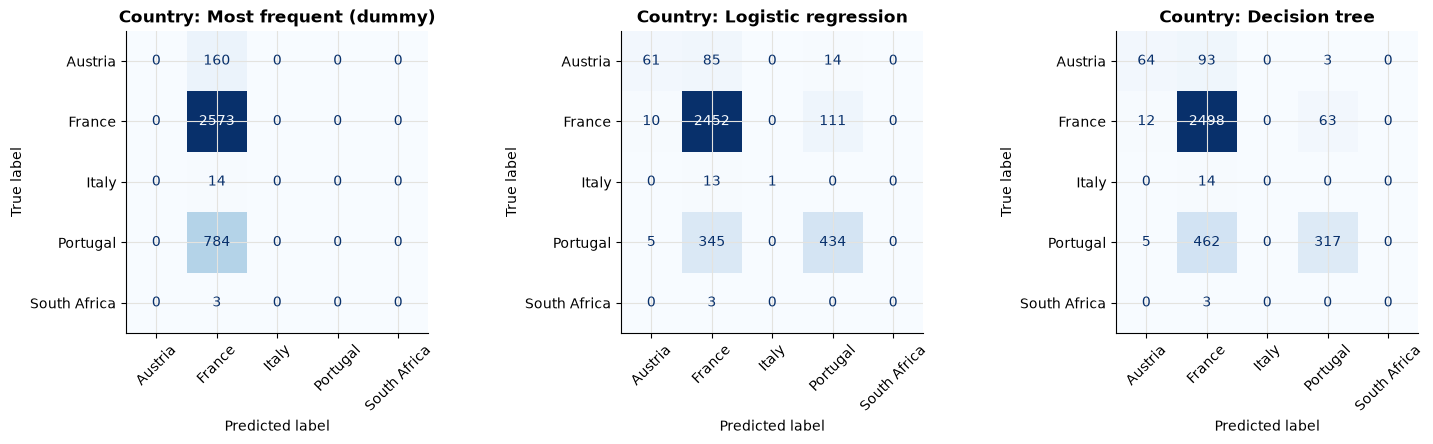

In [24]:
country_models = list(make_models())
fig, axes = plt.subplots(1, len(country_models), figsize=(5 * len(country_models), 4.5))
for ax, name in zip(np.atleast_1d(axes), country_models):
    y_true, y_pred = test_predictions["country", name]
    labels = np.unique(np.concatenate([y_true, y_pred]))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=labels, xticks_rotation=45, cmap="Blues",
        colorbar=False, ax=ax
    )
    ax.set_title(f"Country: {name}")
plt.tight_layout()